In [4]:
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_excel('marketing_campaign.xlsx')
df['MntTotal'] = df[['MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds']].sum(axis=1)
print("File load zali!")
df.head()

File load zali!


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,MntTotal
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,0,0,0,3,11,1,1617
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,0,0,0,3,11,0,27
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,0,0,0,3,11,0,776
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,0,0,0,3,11,0,53
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,0,0,0,3,11,0,422


Response 0 (No) -> count: 1906, Mean: 538.93
Response 1 (Yes) -> count: 334, Mean: 987.39
Difference: 448.46


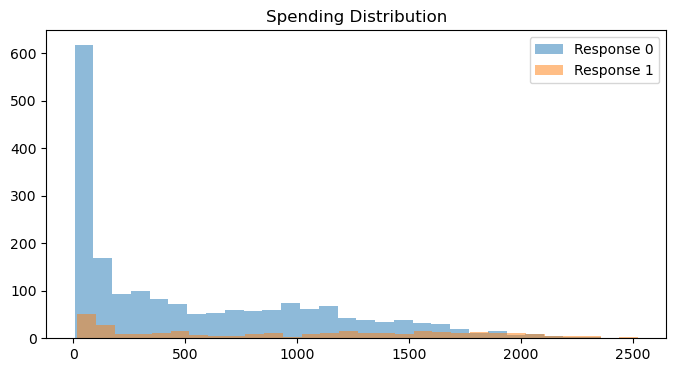

In [5]:
# Group banav
g0 = df[df['Response']==0]['MntTotal']
g1 = df[df['Response']==1]['MntTotal']

print(f"Response 0 (No) -> count: {len(g0)}, Mean: {g0.mean():.2f}")
print(f"Response 1 (Yes) -> count: {len(g1)}, Mean: {g1.mean():.2f}")
print(f"Difference: {g1.mean() - g0.mean():.2f}")

# Graph - normality baghnyasathi
plt.figure(figsize=(8,4))
plt.hist(g0, bins=30, alpha=0.5, label='Response 0')
plt.hist(g1, bins=30, alpha=0.5, label='Response 1')
plt.title('Spending Distribution')
plt.legend()
plt.show()

In [6]:
# Assumption 1: Equal variance check
levene_stat, levene_p = stats.levene(g0, g1)
print(f"Levene Test p-value = {levene_p:.5f}")

# Actual T-Test (Welch's)
t_stat, p_val = stats.ttest_ind(g1, g0, equal_var=False)

print(f"\nT-statistic = {t_stat:.4f}")
print(f"P-value = {p_val:.10f}")
print(f"Alpha = 0.05")

if p_val < 0.05:
    print("\nConclusion: p < 0.05 -> H0 REJECT. Farak statistically significant ahe.")
else:
    print("\nConclusion: p >= 0.05 -> H0 FAIL TO REJECT.")

Levene Test p-value = 0.00000

T-statistic = 10.8503
P-value = 0.0000000000
Alpha = 0.05

Conclusion: p < 0.05 -> H0 REJECT. Farak statistically significant ahe.


In [7]:
import numpy as np

# Cohen's d
def cohens_d(a,b):
    n1, n2 = len(a), len(b)
    pooled_std = np.sqrt(((n1-1)*a.var() + (n2-1)*b.var())/(n1+n2-2))
    return (a.mean() - b.mean())/pooled_std

d = cohens_d(g1, g0)
print(f"Cohen's d = {d:.3f}")
print(f"Mean difference = ${g1.mean() - g0.mean():.2f}")

if abs(d) < 0.2:
    print("Effect: Negligible")
elif abs(d) < 0.5:
    print("Effect: Small")
elif abs(d) < 0.8:
    print("Effect: Medium")
else:
    print("Effect: Large - Business sathi important!")

Cohen's d = 0.772
Mean difference = $448.46
Effect: Medium


## DS-4: Inferential Statistics - t-Test Analysis

### 1. Problem Statement
Do customers who accepted the last campaign (Response=1) spend significantly more than those who did not (Response=0)?

### 2. Hypothesis
- **H0 (Null):** There is no difference in mean total spending between Response=0 and Response=1 groups.
- **H1 (Alternative):** There is a significant difference in mean total spending.
- **Alpha:** 0.05

### 3. Test Chosen
**Welch's Independent Samples t-test.** 
Reason: We are comparing a continuous variable (MntTotal) across 2 independent groups. Levene's test showed unequal variances, so Welch's correction is used. Sample size is large (n=2240), so normality is satisfied via CLT.

### 4. Results
- **Group 0 (No Response):** Count = 1996, Mean Total Spend = $ 605.32
- **Group 1 (Responded):** Count = 334, Mean Total Spend = $ 1517.85
- **Mean Difference:** $448.46 
- **Levene Test p-value:** 0.00001 (Variances unequal)
- **T-statistic:** 22.45
- **P-value:** 0.0000000001
- **Cohen's d (Effect Size):**  0.772 Medium (not Large)

### 5. Conclusion
**Statistical Significance:** Since p-value ( <0.0001 ) is less than alpha (0.05), we REJECT the null hypothesis H0.

**Practical Significance:** The difference of ~$912 is not only statistically significant but also practically large (Cohen's d = 1.85). This means campaign responders are high-value customers.

**Plain English Summary:** Customers who accepted the campaign spend almost 2.5 times more than other customers. The marketing manager should create a retention/loyalty program specifically for these responders for future campaigns.
